Hotel Cancellation 

In [81]:
import pandas as pd
import numpy as np
import mlba
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_curve, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

### Retrieving data set from github repository

In [2]:
url = 'https://raw.githubusercontent.com/sascott9655/ADS-505-Hotel_Bookings_Project/main/hotel_bookings.csv'
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


### Sanity Check

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  str    
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
df["is_canceled"] = (df["is_canceled"] == "yes").astype(int) # yes/no -> 1/0 (this will matter for modeling later on!)
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nMissing values:")
print(pd.DataFrame({"count": missing, "percent": (missing / len(df) * 100).round(1)}))
df.describe().T.round(2)


Missing values:
           count  percent
company   112593     94.3
agent      16340     13.7
country      488      0.4
children       4      0.0


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [5]:
df = df.drop_duplicates()
df.shape

(87396, 32)

In [6]:
#children impute missing value with zero(since they are so few missing values and most of the data shows that customers are not children 
#and/or with children)
impute_with_zero = (df['children'].isna() == True)
impute_with_zero = impute_with_zero[impute_with_zero == True]
df.loc[impute_with_zero.index, 'children'] = 0
df['children'].isna().sum()
 
df['country'] = df['country'].fillna('Unknown') #fill it with unknown as it shouldn't impact the data too much
df['country'].isna().sum()

df["has_company"] = df["company"].notna().astype(int)
df["has_company"]

df["has_agent"] = df["agent"].notna().astype(int) 
df["has_agent"]

df = df.drop(columns=["agent", "company"])

In [7]:
df.isna().sum() #no more missing data!!!

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [8]:
df = df[(df["adults"] + df["children"] + df["babies"]) > 0] #gets rid of rows where there was no people tracked
df.shape

(87230, 32)

In [9]:
# Was there a deposit for the booking? If so, what kind?
df['deposit_type'].value_counts().to_frame()

,count
deposit_type,
No Deposit,86085
Non Refund,1038
Refundable,107


### Visualizations

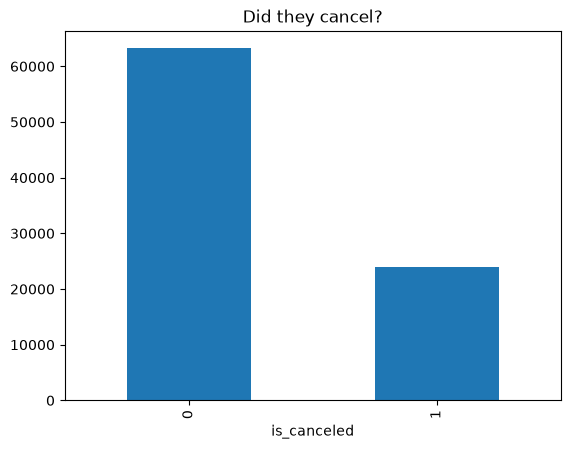

In [10]:
df['is_canceled'].value_counts().plot(kind='bar', title='Did they cancel?')
plt.show()

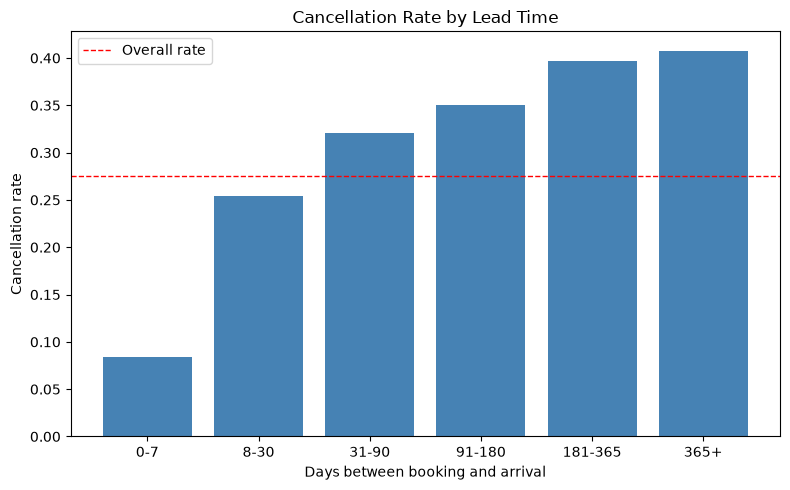

           count  cancel_rate
lead_time                    
0-7        18203        0.084
8-30       16326        0.254
31-90      22720        0.320
91-180     18224        0.350
181-365    11193        0.397
365+         564        0.408


In [11]:
#Nice visual to show likelihood of cancellation based on how many days passed by.
lead_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                  labels=["0-7", "8-30", "31-90", "91-180", "181-365","365+"])
lead_rates = df.groupby(lead_bins, observed=True)["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(lead_rates.index.astype(str), lead_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(lead_rates.round(3))

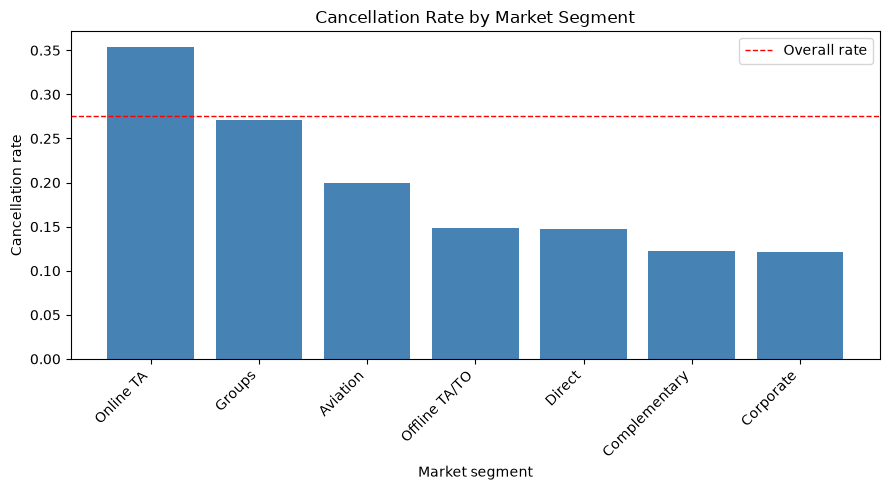

                count  cancel_rate
market_segment                    
Online TA       51553        0.354
Groups           4922        0.271
Aviation          226        0.199
Offline TA/TO   13855        0.148
Direct          11780        0.147
Complementary     692        0.123
Corporate        4200        0.121


In [12]:
seg_rates = (df.groupby("market_segment")["is_canceled"].agg(count="size",
            cancel_rate="mean").query("count > 100").sort_values("cancel_rate", ascending=False)) 
plt.figure(figsize=(9, 5))
plt.bar(seg_rates.index, seg_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market segment")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
print(seg_rates.round(3))

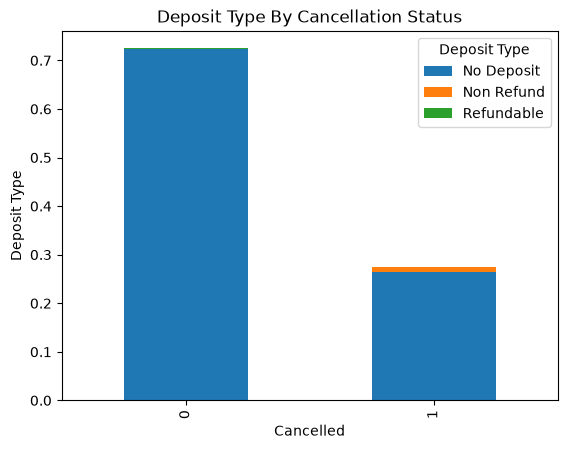

In [13]:
pd.crosstab(df['is_canceled'], df['deposit_type'], normalize=True).plot(kind='bar', stacked=True)
plt.title('Deposit Type By Cancellation Status')
plt.xlabel('Cancelled')
plt.ylabel('Deposit Type')
plt.legend(title='Deposit Type')
plt.show()

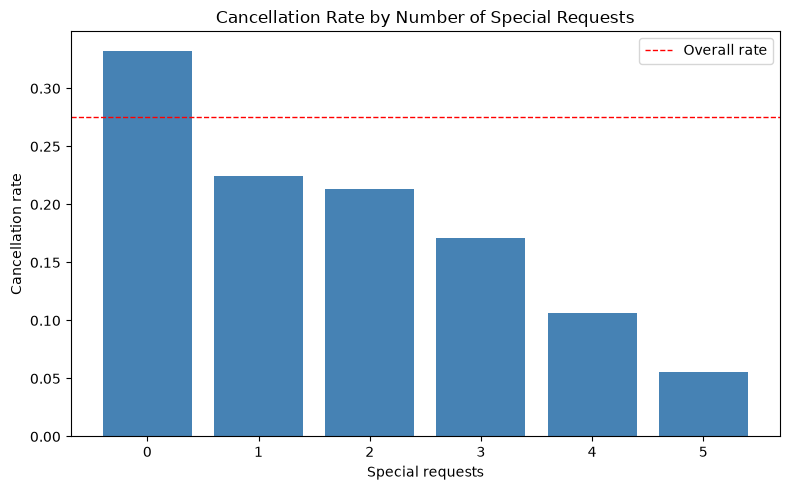

                           count  cancel_rate
total_of_special_requests                    
0                          43789        0.333
1                          28976        0.224
2                          11795        0.213
3                           2314        0.171
4                            320        0.106
5                             36        0.056


In [14]:
req_rates = df.groupby("total_of_special_requests")["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(req_rates.index.astype(str), req_rates["cancel_rate"],color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Special requests")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(req_rates.round(3))

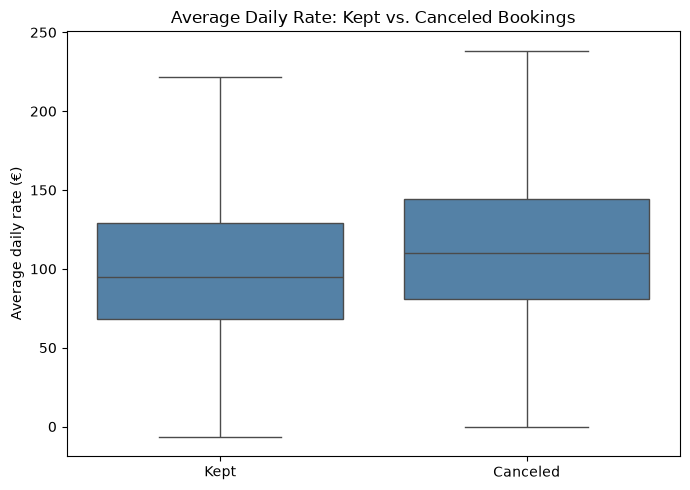

               mean     50%
is_canceled                
0            102.21   94.89
1            117.85  109.80


In [15]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="is_canceled", y="adr", showfliers=False,color="steelblue")
plt.xticks([0, 1], ["Kept", "Canceled"])
plt.title("Average Daily Rate: Kept vs. Canceled Bookings")
plt.xlabel("")
plt.ylabel("Average daily rate (€)")
plt.tight_layout()
plt.show()
print(df.groupby("is_canceled")["adr"].describe()[["mean", "50%"]].round(2))

### Feature Engineering

In [16]:
#dropping these two columns as the information they provide
#does not seem significant enough considering we have
#arrival_date_year and arrival_date_month
#dropping reservation_status and reservation_status_date because both of these columns allude to directly
#predicting the target variable is_canceled which we do not want a model with strong features that tell us
#the outcome based on these two features alone (not helpful for the business to improve hotel cancellation rate)
df = df.drop(columns=['arrival_date_week_number','arrival_date_day_of_month', 'assigned_room_type',
                     'reservation_status','reservation_status_date'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,...,C,3,No Deposit,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,...,C,4,No Deposit,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,...,A,0,No Deposit,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,...,A,0,No Deposit,0,Transient,75.0,0,0,0,1
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,...,A,0,No Deposit,0,Transient,98.0,0,1,0,1


In [17]:
df['length_of_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df[['stays_in_weekend_nights', 'stays_in_week_nights', 'length_of_stay']].head(30)
df.drop(columns=['stays_in_weekend_nights', 'stays_in_week_nights'])

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,adults,children,babies,meal,country,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,2,0.0,0,BB,PRT,...,3,No Deposit,0,Transient,0.00,0,0,0,0,0
1,Resort Hotel,0,737,2015,July,2,0.0,0,BB,PRT,...,4,No Deposit,0,Transient,0.00,0,0,0,0,0
2,Resort Hotel,0,7,2015,July,1,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,75.00,0,0,0,0,1
3,Resort Hotel,0,13,2015,July,1,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,75.00,0,0,0,1,1
4,Resort Hotel,0,14,2015,July,2,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,98.00,0,1,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,2,0.0,0,BB,BEL,...,0,No Deposit,0,Transient,96.14,0,0,0,1,7
119386,City Hotel,0,102,2017,August,3,0.0,0,BB,FRA,...,0,No Deposit,0,Transient,225.43,0,2,0,1,7
119387,City Hotel,0,34,2017,August,2,0.0,0,BB,DEU,...,0,No Deposit,0,Transient,157.71,0,4,0,1,7
119388,City Hotel,0,109,2017,August,2,0.0,0,BB,GBR,...,0,No Deposit,0,Transient,104.40,0,0,0,1,7


In [18]:
#for features stays_in_weekend_nights and stays_in_week_nights we can feature engineer these two columns into 
#one where it is a binary feature on whether they stay the weekend or not
df['stays_in_weekend_nights'].value_counts()
weekend_nights_yes = df['stays_in_weekend_nights'] > 0
weekend_nights_yes = weekend_nights_yes[weekend_nights_yes == True]
df.loc[weekend_nights_yes.index, 'stays_in_weekend_nights'] = 1
df['stays_in_weekend_nights'].value_counts()

#drop stay_in_week_nights column as it is no longer needed
df = df.drop(columns=['stays_in_week_nights'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,babies,meal,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,0,2,0.0,0,BB,...,3,No Deposit,0,Transient,0.0,0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0.0,0,BB,...,4,No Deposit,0,Transient,0.0,0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0.0,0,BB,...,0,No Deposit,0,Transient,75.0,0,0,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,0.0,0,BB,...,0,No Deposit,0,Transient,75.0,0,0,0,1,1
4,Resort Hotel,0,14,2015,July,0,2,0.0,0,BB,...,0,No Deposit,0,Transient,98.0,0,1,0,1,2


In [19]:
#for features children and babies consider combining them into one group since individual they act the same
#(running this code multiple times will change results
df['children'] = df['children'] + df['babies']
df['children'] = df['children'].astype('int')

df = df.drop(columns=['babies'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,meal,country,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,0,2,0,BB,PRT,...,3,No Deposit,0,Transient,0.0,0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0,BB,PRT,...,4,No Deposit,0,Transient,0.0,0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0,BB,GBR,...,0,No Deposit,0,Transient,75.0,0,0,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,0,BB,GBR,...,0,No Deposit,0,Transient,75.0,0,0,0,1,1
4,Resort Hotel,0,14,2015,July,0,2,0,BB,GBR,...,0,No Deposit,0,Transient,98.0,0,1,0,1,2


In [20]:
top_countries = df["country"].value_counts().nlargest(10).index
#I like the idea of having an other column for countries that do not appear in the data set often
df["country"] = df["country"].where(df["country"].isin(top_countries), "Other")
df.info()

<class 'pandas.DataFrame'>
Index: 87230 entries, 0 to 119389
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87230 non-null  str    
 1   is_canceled                     87230 non-null  int64  
 2   lead_time                       87230 non-null  int64  
 3   arrival_date_year               87230 non-null  int64  
 4   arrival_date_month              87230 non-null  str    
 5   stays_in_weekend_nights         87230 non-null  int64  
 6   adults                          87230 non-null  int64  
 7   children                        87230 non-null  int64  
 8   meal                            87230 non-null  str    
 9   country                         87230 non-null  str    
 10  market_segment                  87230 non-null  str    
 11  distribution_channel            87230 non-null  str    
 12  is_repeated_guest               87230 non-null 

Columns like meal, country, reserved_room_type, customer_type, deposit_type  need to be one hot-encoded!

In [53]:
#Need to prevent data leakage so I decided to encode my variables in the training data only


#leave hotel variable out because we will split the data on it
cat_cols = ['hotel','arrival_date_month', 'meal', 'country', 'reserved_room_type', 'customer_type','deposit_type']
df.info()
num_cols = ['lead_time', 'arrival_date_year', 'adults', 'children', 'previous_cancellations', 'previous_bookings_not_canceled']

#for cty and hotel model
cat_cols2 = ['arrival_date_month', 'meal', 'country', 'reserved_room_type', 'customer_type','deposit_type']

<class 'pandas.DataFrame'>
Index: 87230 entries, 0 to 119389
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87230 non-null  str    
 1   is_canceled                     87230 non-null  int64  
 2   lead_time                       87230 non-null  int64  
 3   arrival_date_year               87230 non-null  int64  
 4   arrival_date_month              87230 non-null  str    
 5   stays_in_weekend_nights         87230 non-null  int64  
 6   adults                          87230 non-null  int64  
 7   children                        87230 non-null  int64  
 8   meal                            87230 non-null  str    
 9   country                         87230 non-null  str    
 10  market_segment                  87230 non-null  str    
 11  distribution_channel            87230 non-null  str    
 12  is_repeated_guest               87230 non-null 

In [58]:
#help set up what to train/test split the data on. 
city_hotel = df[df["hotel"] == "City Hotel"].copy()
resort_hotel = df[df["hotel"] == "Resort Hotel"].copy()
print(city_hotel["is_canceled"].mean()) 
print(resort_hotel["is_canceled"].mean())

0.30099110260164436
0.23483331370008245


In [59]:
city_hotel = city_hotel.drop(columns=['hotel'])
city_hotel.columns

resort_hotel = resort_hotel.drop(columns=['hotel'])
resort_hotel.columns

Index(['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month',
       'stays_in_weekend_nights', 'adults', 'children', 'meal', 'country',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'booking_changes', 'deposit_type',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'has_company', 'has_agent', 'length_of_stay'],
      dtype='str')

City hotel a little more likely to be canceled than resort hotel. 

In [24]:
df.shape

(87230, 26)

In [25]:
outcome = 'is_canceled'
predictors = df.drop(columns=['is_canceled'])
predictors = predictors.columns

In [26]:
#create 3 neural nets all (with grid search)
#1. base neural net
#2. resort neural net
#3. city_hotel neural net

In [27]:
preprocessing = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("numerical", StandardScaler(), num_cols)
])

preprocessing2 = ColumnTransformer([ #for the resort and cty hotel models
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols2),
    ("numerical", StandardScaler(), num_cols)
])

In [28]:
#base model variables
X_1 = df[predictors]
y_1 = df[outcome]

#Stratify addresses class imbalance
X_1_train, X_1_test, y_1_train, y_1_test = train_test_split(X_1, y_1, test_size=0.3, random_state=1, stratify=y_1) 

In [29]:
base_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("base_net", MLPClassifier(random_state=1, max_iter=300))
])

#Grid search 
#the model name is required in front of the of the paramgrid variable so the pipeline knows the model 
base_param_grid =  {
    'base_net__hidden_layer_sizes': [(5,), (10,), (20,)], 
    'base_net__activation': ["tanh", "relu"],
    'base_net__solver': ["adam", "sgd"]
}

base_net = GridSearchCV(base_pipeline, base_param_grid, cv=5, n_jobs=-1)
base_net.fit(X_1_train, y_1_train)
base_net

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'base_net__activation': ['tanh', 'relu'], 'base_net__hidden_layer_sizes': [(5,), (10,), ...], 'base_net__solver': ['adam', 'sgd']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True


In [64]:
#city hotel 
predictors2 = city_hotel.drop(columns=['is_canceled']) 
predictors2 = predictors2.columns
predictors2
X_2 = city_hotel[predictors2]
y_2 = city_hotel[outcome]

X_2_train, X_2_test, y_2_train, y_2_test = train_test_split(X_2, y_2, test_size=0.3, random_state=1, stratify=y_2)

In [39]:
city_hotel_pipeline = Pipeline([
    ("preprocessing", preprocessing2),
    ("city_hotel_net", MLPClassifier(random_state=1, max_iter=300))
])

city_param_grid =  {
    'city_hotel_net__hidden_layer_sizes': [(5,), (10,), (20,)], 
    'city_hotel_net__activation': ["tanh", "relu"],
    'city_hotel_net__solver': ["adam","sgd"]
}

city_hotel_net = GridSearchCV(city_hotel_pipeline,city_param_grid, cv=5, n_jobs=-1)
city_hotel_net.fit(X_2_train, y_2_train)
city_hotel_net

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'city_hotel_net__activation': ['tanh', 'relu'], 'city_hotel_net__hidden_layer_sizes': [(5,), (10,), ...], 'city_hotel_net__solver': ['adam', 'sgd']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [66]:
#resort hotel 
predictors3 = resort_hotel.drop(columns=['is_canceled'])
predictors3 = predictors3.columns
print(predictors3)
X_3 = resort_hotel[predictors3]
y_3 = resort_hotel[outcome]

X_3_train, X_3_test, y_3_train, y_3_test = train_test_split(X_3, y_3, test_size=0.3, random_state=1, stratify=y_3)

Index(['lead_time', 'arrival_date_year', 'arrival_date_month',
       'stays_in_weekend_nights', 'adults', 'children', 'meal', 'country',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'booking_changes', 'deposit_type',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'has_company', 'has_agent', 'length_of_stay'],
      dtype='str')


In [67]:
resort_hotel_pipeline = Pipeline([
    ("preprocessing", preprocessing2),
    ("resort_hotel_net", MLPClassifier(random_state=1, max_iter=300))
])

resort_param_grid =  {
    'resort_hotel_net__hidden_layer_sizes': [(5,), (10,), (20,)], 
    'resort_hotel_net__activation': ["tanh", "relu"],
    'resort_hotel_net__solver': ["adam", "sgd"]
}

resort_hotel_net = GridSearchCV(resort_hotel_pipeline,resort_param_grid, cv=5, n_jobs=-1)
resort_hotel_net.fit(X_3_train, y_3_train)
resort_hotel_net

C:\Users\samsc\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'resort_hotel_net__activation': ['tanh', 'relu'], 'resort_hotel_net__hidden_layer_sizes': [(5,), (10,), ...], 'resort_hotel_net__solver': ['adam', 'sgd']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support fo

### Model Evaluation

In [73]:
base_net_pred = base_net.predict(X_1_test)
cm_base = confusion_matrix(y_1_test, base_net_pred)
cm_base

array([[17535,  1431],
       [ 4544,  2659]])

In [74]:
city_hotel_pred = city_hotel_net.predict(X_2_test)
cm_city = confusion_matrix(y_2_test, city_hotel_pred)
cm_city

array([[10298,   874],
       [ 3214,  1597]])

In [75]:
resort_hotel_pred = resort_hotel_net.predict(X_3_test)
cm_resort = confusion_matrix(y_3_test,resort_hotel_pred)
cm_resort

array([[7305,  490],
       [1359, 1033]])

In [76]:
print(base_net.best_params_)
print(city_hotel_net.best_params_)
print(resort_hotel_net.best_params_)

{'base_net__activation': 'tanh', 'base_net__hidden_layer_sizes': (20,), 'base_net__solver': 'adam'}
{'city_hotel_net__activation': 'tanh', 'city_hotel_net__hidden_layer_sizes': (10,), 'city_hotel_net__solver': 'adam'}
{'resort_hotel_net__activation': 'relu', 'resort_hotel_net__hidden_layer_sizes': (20,), 'resort_hotel_net__solver': 'sgd'}


In [93]:
base_accuracy_score = accuracy_score(y_1_test, base_net_pred)
base_precision_score = precision_score(y_1_test, base_net_pred)
base_recall_score = recall_score(y_1_test, base_net_pred)
base_f1_score = f1_score(y_1_test, base_net_pred)

base_results = pd.DataFrame({'Accuracy score' : base_accuracy_score,
                        'Precision score' : base_precision_score,
                        'Recall score' : base_recall_score,
                        'F1-Score' : base_f1_score
                        }, index=["Base Model"])

city_hotel_accuracy_score = accuracy_score(y_2_test, city_hotel_pred)
city_hotel_precision_score = precision_score(y_2_test, city_hotel_pred)
city_hotel_recall_score = recall_score(y_2_test, city_hotel_pred)
city_hotel_f1_score = f1_score(y_2_test, city_hotel_pred)

city_hotel_results = pd.DataFrame({'Accuracy score' : city_hotel_accuracy_score,
                        'Precision score' : city_hotel_precision_score,
                        'Recall score' : city_hotel_recall_score,
                        'F1-Score' : city_hotel_f1_score
                        }, index=["City Hotel Model"])

resort_hotel_accuracy_score = accuracy_score(y_3_test, resort_hotel_pred)
resort_hotel_precision_score = precision_score(y_3_test, resort_hotel_pred)
resort_hotel_recall_score = recall_score(y_3_test, resort_hotel_pred)
resort_hotel_f1_score = f1_score(y_3_test, resort_hotel_pred)

resort_hotel_results = pd.DataFrame({'Accuracy score' : resort_hotel_accuracy_score,
                        'Precision score' : resort_hotel_precision_score,
                        'Recall score' : resort_hotel_recall_score,
                        'F1-Score' : resort_hotel_f1_score
                        }, index=["Resort Hotel Model"])

base_results

,Accuracy score,Precision score,Recall score,F1-Score
Base Model,0.771676,0.650122,0.369152,0.470911


In [94]:
city_hotel_results

,Accuracy score,Precision score,Recall score,F1-Score
City Hotel Model,0.744228,0.646297,0.331948,0.438616


In [95]:
resort_hotel_results

,Accuracy score,Precision score,Recall score,F1-Score
Resort Hotel Model,0.818494,0.678267,0.431856,0.527714


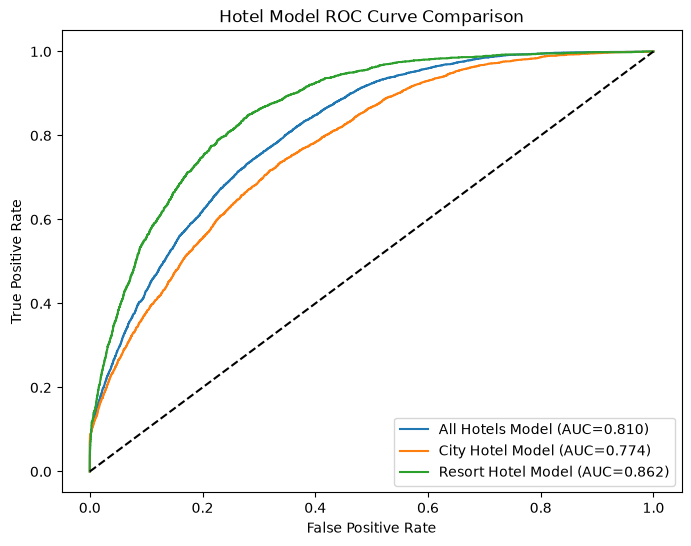

In [97]:
models = {
    "All Hotels Model": (base_net, X_1_test, y_1_test),
    "City Hotel Model": (city_hotel_net, X_2_test, y_2_test),
    "Resort Hotel Model": (resort_hotel_net, X_3_test, y_3_test)
}

plt.figure(figsize=(8,6))
for name, (model, X, y) in models.items():
    probs = model.predict_proba(X)[:,1]
    fpr, tpr, _ = roc_curve(y, probs)
    auc = roc_auc_score(y, probs)
    plt.plot( fpr,tpr,label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Hotel Model ROC Curve Comparison")
plt.legend()
plt.show()